# Phase 1. Exploratory Data Analysis

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score


In [2]:
# Load the dataset
df = pd.read_csv('../data/cs-training.csv')
df.shape

(150000, 12)

In [3]:
data = df.copy()

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  NumberOfDep

In [5]:
data.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [6]:
data.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,150000.0,75000.500000,43301.414527,1.0,37500.750000,75000.500000,112500.250000,150000.0
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0


## Distribution Analysis

### Missing Values Analysis

In [71]:
data.isnull().sum().sort_values(ascending=False)

NumberOfDependents                      3924
age                                        1
SeriousDlqin2yrs                           0
RevolvingUtilizationOfUnsecuredLines       0
NumberOfTime30-59DaysPastDueNotWorse       0
Unnamed: 0                                 0
DebtRatio                                  0
MonthlyIncome                              0
NumberOfTimes90DaysLate                    0
NumberOfOpenCreditLinesAndLoans            0
NumberRealEstateLoansOrLines               0
NumberOfTime60-89DaysPastDueNotWorse       0
total-number_of_lates                      0
log_transformed-montly-income              0
dtype: int64

In [8]:
data[['MonthlyIncome', 'NumberOfDependents']].isnull().sum()

MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64

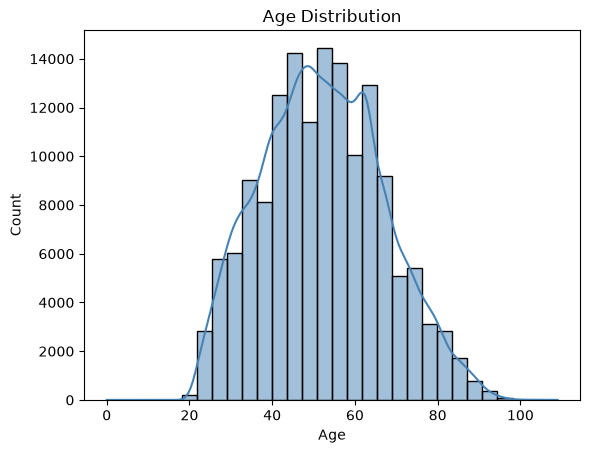

count    150000.00
mean         52.30
std          14.77
min           0.00
25%          41.00
50%          52.00
75%          63.00
max         109.00
Name: age, dtype: float64


In [9]:
# Age Distribution
sns.histplot(data['age'], bins=30, kde=True, color='steelblue')
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()
print(data['age'].describe().round(2))

In [10]:
# Delete columns where age is less than 18, as they are not valid for credit risk prediction
data['age'] = data['age'].drop(data[data['age'] < 18].index)

In [11]:
data[data['age'] >= 90]

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
208,209,0,0.046640,92.0,1,0.034327,2650.0,13,0,0,0,0.0
320,321,0,0.016478,92.0,0,10.000000,NaN,3,0,0,0,0.0
387,388,0,0.003895,90.0,0,876.000000,NaN,11,0,1,0,0.0
436,437,0,0.007000,97.0,0,3.000000,NaN,2,0,0,0,NaN
509,510,0,1.000000,91.0,0,0.000000,NaN,3,0,0,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
149489,149490,0,0.030269,90.0,0,0.009654,5800.0,4,0,0,0,0.0
149651,149652,0,0.003418,90.0,0,0.001656,2414.0,4,0,0,0,0.0
149658,149659,0,0.003088,91.0,0,0.000791,3793.0,5,0,0,0,0.0
149818,149819,0,0.016420,90.0,0,0.077838,9750.0,10,0,0,0,0.0


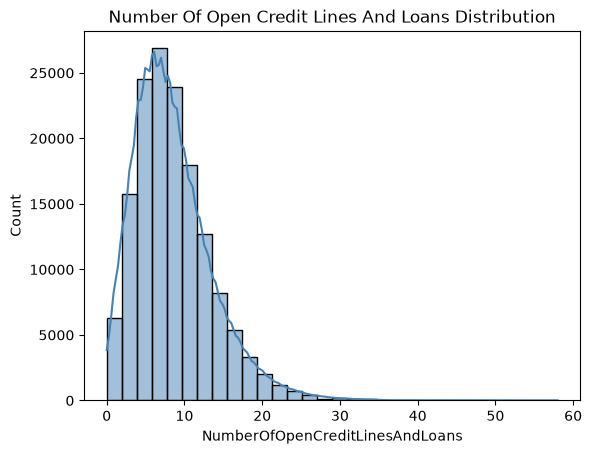

count    150000.00
mean          8.45
std           5.15
min           0.00
25%           5.00
50%           8.00
75%          11.00
max          58.00
Name: NumberOfOpenCreditLinesAndLoans, dtype: float64


In [12]:
# Number Of Open Credit Lines And Loans Distribution
sns.histplot(data['NumberOfOpenCreditLinesAndLoans'], bins=30, kde=True, color="steelblue")
plt.title("Number Of Open Credit Lines And Loans Distribution")
plt.xlabel("NumberOfOpenCreditLinesAndLoans")
plt.ylabel("Count")
plt.show()
print(data['NumberOfOpenCreditLinesAndLoans'].describe().round(2))

In [13]:
# Checking strange values in NumberOfOpenCreditLinesAndLoans
data[data['NumberOfOpenCreditLinesAndLoans'] == 58]

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
30587,30588,0,0.003032,53.0,0,5.967504,8000.0,58,0,54,0,0.0


## Outlier Detection

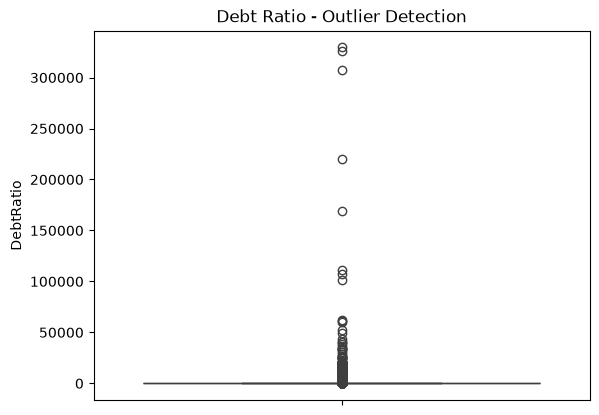

In [14]:
sns.boxplot(data['DebtRatio'])
plt.title("Debt Ratio - Outlier Detection")
plt.show()

In [15]:
# Fill missed values with median for checking outliers
median_imputer = data['MonthlyIncome'].median()
data['MonthlyIncome'] = data['MonthlyIncome'].fillna(median_imputer)

In [16]:
print(data['MonthlyIncome'].isna().sum())

0


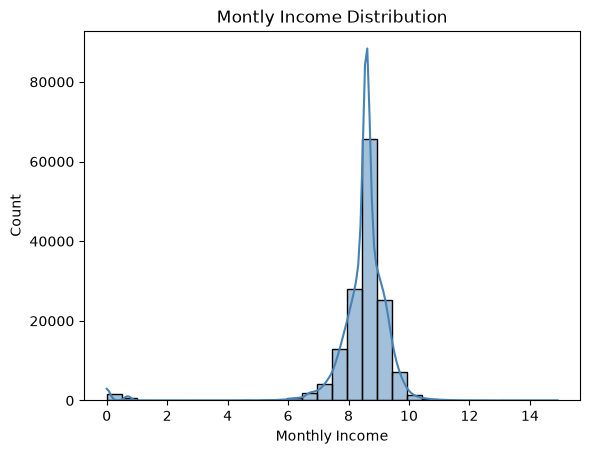

In [17]:
sns.histplot(np.log1p(data['MonthlyIncome']), bins=30, kde=True, color="steelblue")
plt.title("Montly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Count")
plt.show()

<Axes: xlabel='DebtRatio', ylabel='Count'>

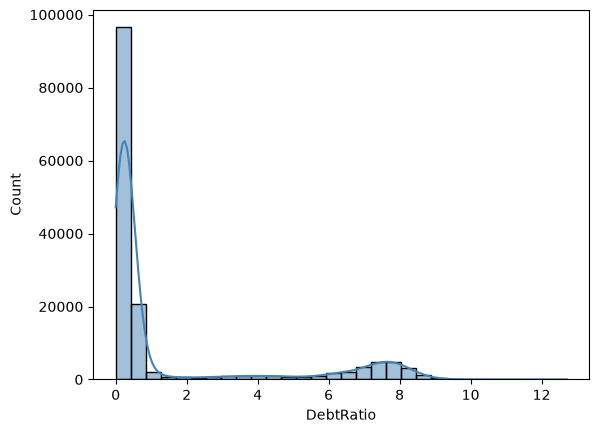

In [27]:
# Checking log-transformed DebtRatio distribution
sns.histplot(np.log1p(data['DebtRatio']), bins=30, kde=True, color="steelblue")

In [18]:
# IQR explicit calculation
for col in ['MonthlyIncome', 'DebtRatio', 'RevolvingUtilizationOfUnsecuredLines', 'NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate', 'NumberOfDependents']:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((data[col] < lower) | (data[col] > upper)).sum()

    print(f"{col}")
    print(f"  Q1 = {Q1:.1f}  |  Q3 = {Q3:.1f}  |  IQR = {IQR:.1f}")
    print(f"  Lower bound = {lower:.1f}  |  Upper bound = {upper:.1f}")
    print(f"  Outliers    = {n_out} rows")
    print()

MonthlyIncome
  Q1 = 3903.0  |  Q3 = 7400.0  |  IQR = 3497.0
  Lower bound = -1342.5  |  Upper bound = 12645.5
  Outliers    = 9149 rows

DebtRatio
  Q1 = 0.2  |  Q3 = 0.9  |  IQR = 0.7
  Lower bound = -0.9  |  Upper bound = 1.9
  Outliers    = 31311 rows

RevolvingUtilizationOfUnsecuredLines
  Q1 = 0.0  |  Q3 = 0.6  |  IQR = 0.5
  Lower bound = -0.8  |  Upper bound = 1.4
  Outliers    = 763 rows

NumberOfTime30-59DaysPastDueNotWorse
  Q1 = 0.0  |  Q3 = 0.0  |  IQR = 0.0
  Lower bound = 0.0  |  Upper bound = 0.0
  Outliers    = 23982 rows

NumberOfTime60-89DaysPastDueNotWorse
  Q1 = 0.0  |  Q3 = 0.0  |  IQR = 0.0
  Lower bound = 0.0  |  Upper bound = 0.0
  Outliers    = 7604 rows

NumberOfTimes90DaysLate
  Q1 = 0.0  |  Q3 = 0.0  |  IQR = 0.0
  Lower bound = 0.0  |  Upper bound = 0.0
  Outliers    = 8338 rows

NumberOfDependents
  Q1 = 0.0  |  Q3 = 1.0  |  IQR = 1.0
  Lower bound = -1.5  |  Upper bound = 2.5
  Outliers    = 13336 rows



In [19]:
cols = [
    'MonthlyIncome',
    'DebtRatio',
    'RevolvingUtilizationOfUnsecuredLines',
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfDependents'
]

print(data[cols].describe(percentiles=[0.95, 0.99, 0.999]).T)

                                         count         mean           std  \
MonthlyIncome                         150000.0  6418.454920  12890.395542   
DebtRatio                             150000.0   353.005076   2037.818523   
RevolvingUtilizationOfUnsecuredLines  150000.0     6.048438    249.755371   
NumberOfTime30-59DaysPastDueNotWorse  150000.0     0.421033      4.192781   
NumberOfTime60-89DaysPastDueNotWorse  150000.0     0.240387      4.155179   
NumberOfTimes90DaysLate               150000.0     0.265973      4.169304   
NumberOfDependents                    146076.0     0.757222      1.115086   

                                      min      95%           99%      99.9%  \
MonthlyIncome                         0.0  13500.0  23000.000000  72759.157   
DebtRatio                             0.0   2449.0   4979.040000  10613.074   
RevolvingUtilizationOfUnsecuredLines  0.0      1.0      1.092956   1571.006   
NumberOfTime30-59DaysPastDueNotWorse  0.0      2.0      4.000000   

In [35]:
for col in ['DebtRatio', 'RevolvingUtilizationOfUnsecuredLines']:
    print(f"\n{col}")
    print('Above 99th percentile:',
          (data[col] > data[col].quantile(0.99)).sum())
    print('Above 99.9th percentile:',
          (data[col] > data[col].quantile(0.999)).sum())
    print('Maximum:', data[col].max())


DebtRatio
Above 99th percentile: 1500
Above 99.9th percentile: 150
Maximum: 329664.0

RevolvingUtilizationOfUnsecuredLines
Above 99th percentile: 1500
Above 99.9th percentile: 150
Maximum: 50708.0


In [39]:
# Checking the rows with high values of 'DebtRatio'
data[
    data['DebtRatio'] > 
    data['DebtRatio'].quantile(0.999)
]

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
90,91,0,0.039388,51.0,0,15466.0,0.0,7,0,0,0,0.0
844,845,0,0.734284,45.0,0,11311.0,0.0,6,0,2,1,0.0
1156,1157,0,0.926060,48.0,1,12546.0,5400.0,8,0,4,0,0.0
4854,4855,0,0.000000,56.0,0,168835.0,5400.0,10,0,3,0,2.0
7513,7514,0,0.152293,71.0,0,110952.0,5400.0,9,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
147216,147217,0,0.845973,68.0,0,10752.0,5400.0,26,0,3,0,0.0
147310,147311,0,0.173502,69.0,0,12403.0,5400.0,31,0,9,0,0.0
147773,147774,1,0.412257,40.0,0,12702.0,5400.0,12,0,2,0,0.0
148872,148873,0,0.897637,47.0,2,20351.0,5400.0,9,0,5,0,2.0


In [37]:
# Checking the rows with high values of 'RevolvingUtilizationOfUnsecuredLines'
data[
    data['RevolvingUtilizationOfUnsecuredLines'] > 
    data['RevolvingUtilizationOfUnsecuredLines'].quantile(0.999)
]

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
293,294,0,2340.0,45.0,0,0.339333,8333.0,7,0,2,0,2.0
697,698,1,2066.0,58.0,0,0.271121,6000.0,8,1,1,0,1.0
2331,2332,0,6324.0,59.0,0,0.136673,11318.0,4,0,1,0,1.0
4278,4279,0,1982.0,33.0,0,0.144982,8000.0,4,0,0,0,0.0
4793,4794,0,3746.0,52.0,2,0.481353,2600.0,5,0,1,0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...
144887,144888,1,8328.0,39.0,0,21395.000000,5400.0,9,0,2,1,0.0
145587,145588,0,7452.0,52.0,0,0.351365,10000.0,5,0,2,0,3.0
149102,149103,0,6109.0,43.0,0,0.229902,12500.0,9,0,2,0,0.0
149160,149161,0,22000.0,38.0,0,1.080020,3973.0,7,0,2,0,3.0


In [38]:
data[data['RevolvingUtilizationOfUnsecuredLines'] == 50708.0]

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
85489,85490,0,50708.0,55.0,0,0.221757,38000.0,7,0,2,0,0.0


In [20]:
late_cols = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate'
]

for col in late_cols:
    print(f"\n{col}")
    print(data[col].value_counts().sort_index().tail(10))
    print("Count equal to 98:", (data[col] == 98).sum())


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
6     140
7      54
8      25
9      12
10      4
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64
Count equal to 98: 264

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
3     318
4     105
5      34
6      16
7       9
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64
Count equal to 98: 264

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
9      19
10      8
11      5
12      2
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64
Count equal to 98: 264


In [21]:
# Analysing DebtRatio with combination of other columns to find outliers
data.nlargest(10, 'DebtRatio')[
    ['DebtRatio', 'MonthlyIncome', 'RevolvingUtilizationOfUnsecuredLines']
]

,DebtRatio,MonthlyIncome,RevolvingUtilizationOfUnsecuredLines
60152,329664.0,5400.0,0.000000
36600,326442.0,5400.0,0.001782
127047,307001.0,5400.0,0.034290
58900,220516.0,5400.0,0.182640
4854,168835.0,5400.0,0.000000
7513,110952.0,5400.0,0.152293
103041,106885.0,5400.0,0.364845
69845,101320.0,5400.0,0.386451
66785,61907.0,5400.0,1.000000
53682,61106.5,1.0,1.000000


In [33]:
data.nlargest(250, 'RevolvingUtilizationOfUnsecuredLines')[
    ['RevolvingUtilizationOfUnsecuredLines', 'DebtRatio', 'MonthlyIncome']
]

,RevolvingUtilizationOfUnsecuredLines,DebtRatio,MonthlyIncome
85489,50708.000000,0.221757,38000.0
31414,29110.000000,0.402560,10000.0
16956,22198.000000,2312.000000,5400.0
149160,22000.000000,1.080020,3973.0
149279,20514.000000,0.062102,9902.0
...,...,...,...
104426,6.425716,6842.000000,5400.0
30874,6.000000,0.015711,4200.0
85939,5.377748,2463.000000,5400.0
51576,5.361137,0.059486,31166.0


In [23]:
data.nlargest(10, 'MonthlyIncome')[
    ['MonthlyIncome', 'DebtRatio', 'RevolvingUtilizationOfUnsecuredLines']
]

,MonthlyIncome,DebtRatio,RevolvingUtilizationOfUnsecuredLines
73763,3008750.0,0.001470,0.007328
137140,1794060.0,0.002776,0.000000
111365,1560100.0,0.004013,0.163856
50640,1072500.0,0.004537,0.469025
122543,835040.0,0.000147,0.041599
123291,730483.0,0.005570,0.226333
93564,702500.0,0.008268,0.071628
96549,699530.0,0.003698,0.064155
119136,649587.0,0.001313,0.151329
37078,629000.0,0.000000,0.000000


In [24]:
data.nlargest(10, 'NumberOfTime30-59DaysPastDueNotWorse')[
    ['NumberOfTime30-59DaysPastDueNotWorse', 'MonthlyIncome', 'DebtRatio', 'RevolvingUtilizationOfUnsecuredLines']
]

,NumberOfTime30-59DaysPastDueNotWorse,MonthlyIncome,DebtRatio,RevolvingUtilizationOfUnsecuredLines
1733,98,2700.0,0.0,1.0
2286,98,5400.0,0.0,1.0
3884,98,5400.0,12.0,1.0
4417,98,0.0,0.0,1.0
4705,98,2000.0,0.0,1.0
5073,98,1500.0,0.0,1.0
6280,98,7500.0,0.0,1.0
7032,98,1647.0,0.0,1.0
7117,98,5400.0,21.0,1.0
7687,98,5400.0,0.0,1.0


In [25]:
# Delete columns where NumberOfTime60-89DaysPastDueNotWorse is greater than or equal to 90, and MonthlyIncome and DebtRatio are equal to 0
col = data[
    (data['NumberOfTime60-89DaysPastDueNotWorse'] > 90) & 
    (data['NumberOfTime30-59DaysPastDueNotWorse'] > 90) &
    (data['NumberOfTimes90DaysLate'] > 90) &
    (data['MonthlyIncome'] == 0) &
    (data['DebtRatio'] == 0)]
col 

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
4417,4418,0,1.0,21.0,98,0.0,0.0,0,98,0,98,0.0
23604,23605,0,1.0,21.0,98,0.0,0.0,0,98,0,98,0.0
33165,33166,1,1.0,22.0,98,0.0,0.0,0,98,0,98,0.0
49326,49327,1,1.0,22.0,98,0.0,0.0,0,98,0,98,0.0
57857,57858,0,1.0,21.0,98,0.0,0.0,0,98,0,98,0.0
112110,112111,0,1.0,22.0,98,0.0,0.0,0,98,0,98,0.0
124137,124138,0,1.0,25.0,98,0.0,0.0,0,98,0,98,0.0


## Feature Correlations

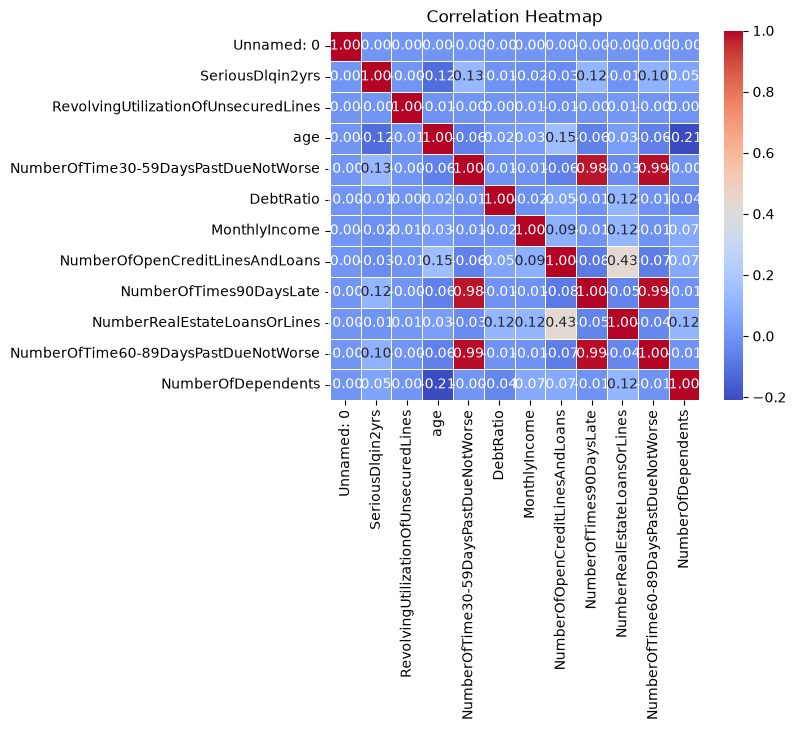

In [43]:
# Full correlation heatmap
corr = data.corr().round(2)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, square=True)
plt.title("Correlation Heatmap")
plt.show()

## Class Imbalance

In [45]:
# Naive baseline
most_common = data['SeriousDlqin2yrs'].mode()[0]
naive_acc = (data['SeriousDlqin2yrs'] == most_common).mean()
print(f"Majority class: {most_common}")
print(f"Naive accuracy: {naive_acc:.1%}")

Majority class: 0
Naive accuracy: 93.3%


In [53]:
# Setup Demo
X_demo = data[['DebtRatio', "RevolvingUtilizationOfUnsecuredLines"]]
y_demo = data['SeriousDlqin2yrs']

# without class weight
model = LogisticRegression(max_iter=1000, random_state=42) # creating the brain
model.fit(X_demo, y_demo) # training the brain
pred = model.predict(X_demo)
print("Without class_weight='balanced")
print("-"*45)
print(f"ROC_AUC curve: {roc_auc_score(y_demo, pred)}")
print(f"Classification report: \n{classification_report(y_demo, pred)}")

Without class_weight
---------------------------------------------
ROC_AUC curve: 0.5
Classification report: 
              precision    recall  f1-score   support

           0       0.93      1.00      0.97    139974
           1       0.00      0.00      0.00     10026

    accuracy                           0.93    150000
   macro avg       0.47      0.50      0.48    150000
weighted avg       0.87      0.93      0.90    150000



c:\Users\Ali\Desktop\credict_risk_prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ali\Desktop\credict_risk_prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Ali\Desktop\credict_risk_prediction\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

In [55]:
# with class weight
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42) # creating the brain
model.fit(X_demo, y_demo) # training the brain
pred_new = model.predict(X_demo)
print("With class_weight='balanced")
print("-"*45)
print(f"ROC_AUC curve: {roc_auc_score(y_demo, pred_new)}")
print(f"Classification report: \n{classification_report(y_demo, pred_new)}")

With class_weight='balanced
---------------------------------------------
ROC_AUC curve: 0.5132637375238971
Classification report: 
              precision    recall  f1-score   support

           0       0.94      0.15      0.26    139974
           1       0.07      0.88      0.13     10026

    accuracy                           0.20    150000
   macro avg       0.51      0.51      0.19    150000
weighted avg       0.89      0.20      0.25    150000



## Feature Engineering 
Create 2 new features from existing columns
These features potentially can help to improce model's performance

In [59]:
# Total number of lates
data['total-number_of_lates'] = data['NumberOfTime30-59DaysPastDueNotWorse'] + data['NumberOfTime60-89DaysPastDueNotWorse'] + data['NumberOfTimes90DaysLate']

In [ ]:
# Log-transformed Montly Income
data['log_transformed-montly-income'] = np.log1p(data['MonthlyIncome'])

In [67]:
new_features = ['total-number_of_lates', 'log_transformed-montly-income']

data[new_features].describe()

,total-number_of_lates,log_transformed-montly-income
count,150000.000000,150000.000000
mean,0.927393,8.447405
std,12.466204,1.195796
min,0.000000,0.000000
25%,0.000000,8.269757
50%,0.000000,8.594339
75%,0.000000,8.909370
max,294.000000,14.917036


In [70]:
# Save model_table which ready for modelling
data.to_csv("../outputs/model_table.csv", index=False)

print("model_table.csv saved")
print(f"Shape  : {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print("\nReady for next phase")

model_table.csv saved
Shape  : (150000, 12)
Columns: ['Unnamed: 0', 'SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents']

Ready for next phase
